# POS Tagging for the Healthcare Domain
**Task:** Develop a POS tagging system for a specialized domain (Healthcare), compare
rule-based vs statistical (HMM) POS tagging, and analyze the effect of domain-specific
vocabulary on tagging accuracy.

- **Data:** MTSamples medical transcriptions (Kaggle: tboyle10/medicaltranscriptions)
- **Rule-based tagger:** word lists + medical lexicon + suffix rules
- **Statistical tagger:** Hidden Markov Model trained on the NLTK Penn Treebank sample
  (general HMM), and the same HMM trained with extra healthcare sentences (adapted HMM)
- **Reference tags:** produced automatically by spaCy `en_core_web_sm` (silver labels,
  NOT manually verified gold labels). All scores measure agreement with spaCy.

In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ")
os.environ["KAGGLE_KEY"] = getpass("Kaggle API key: ")

Kaggle username: NLP2copy
Kaggle API key: ··········


In [ ]:
!pip install -q -U kaggle
!kaggle datasets download -d tboyle10/medicaltranscriptions
!unzip -o -q medicaltranscriptions.zip

Dataset URL: https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions
License(s): CC0-1.0
medicaltranscriptions.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import pandas as pd
df = pd.read_csv("mtsamples.csv")
print(df.shape)
df.head()

(4999, 6)


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [ ]:
!pip install -q nltk spacy scikit-learn pandas matplotlib seaborn
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 53.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import nltk
nltk.download('punkt') #for tokenization
nltk.download('punkt_tab')
nltk.download('treebank')
nltk.download('universal_tagset')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package treebank to /root/nltk_data...
[nltk_data]   Package treebank is already up-to-date!
[nltk_data] Downloading package universal_tagset to /root/nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


True

In [ ]:
import spacy, re, random
import pandas as pd
import numpy as np
from collections import Counter
from nltk.corpus import treebank
from nltk.tag import map_tag
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.tag.hmm import HiddenMarkovModelTrainer
from nltk.probability import LidstoneProbDist
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

nlp = spacy.load("en_core_web_sm")
random.seed(42)

In [ ]:
# Map spaCy's POS tags to the Universal tagset used by NLTK's Treebank (the HMM's training data).
# In the Treebank's Universal tagset, subordinating conjunctions (because, if, while, after...)
# are ADP and CONJ means coordinating conjunctions only, so SCONJ -> ADP.
SPACY_TO_UNIVERSAL = {
    "NOUN": "NOUN", "PROPN": "NOUN",
    "VERB": "VERB", "AUX": "VERB",
    "ADJ": "ADJ",
    "ADV": "ADV",
    "ADP": "ADP",
    "DET": "DET",
    "NUM": "NUM",
    "PRON": "PRON",
    "CCONJ": "CONJ", "SCONJ": "ADP",
    "PART": "PRT",
    "PUNCT": ".",
    "INTJ": "X", "SYM": "X", "X": "X", "SPACE": "X"
}

def to_universal(tag):
    return SPACY_TO_UNIVERSAL.get(tag, "X")

In [ ]:
# Build a reproducible sample using document-level separation to reduce leakage.
# Use all available reports, not only the first 300 rows. One sentence is selected per report.

df = pd.read_csv("mtsamples.csv").dropna(subset=["transcription"]).reset_index(drop=True)

sentences_by_doc = {}
seen_sentences = set()
for doc_id, text in enumerate(df["transcription"]):
    doc_sentences = []
    for sentence in sent_tokenize(str(text)):
        sentence = " ".join(sentence.split())
        word_count = len(sentence.split())
        key = sentence.lower()
        if 4 <= word_count <= 40 and key not in seen_sentences:
            seen_sentences.add(key)
            doc_sentences.append(sentence)
    if doc_sentences:
        sentences_by_doc[doc_id] = doc_sentences

# Shuffle report IDs with a fixed seed; select one usable sentence from each report.
random.seed(42)
doc_ids = list(sentences_by_doc)
random.shuffle(doc_ids)
assert len(doc_ids) >= 200, (
    f"Only {len(doc_ids)} reports contain a usable unique sentence; need at least 200."
)
selected_docs = doc_ids[:200]
healthcare_pool = [random.choice(sentences_by_doc[doc_id]) for doc_id in selected_docs]
healthcare_doc_ids = selected_docs

print(f"Reports with usable sentences across the full dataset: {len(sentences_by_doc)}")
print(f"Selected sentences: {len(healthcare_pool)} from {len(set(healthcare_doc_ids))} distinct reports")
print("Sample sentences:")
for sentence in healthcare_pool[:5]:
    print("-", sentence)


Reports with usable sentences across the full dataset: 2345
Selected sentences: 200 from 200 distinct reports
Sample sentences:
- Ankle brachial index is 1.06.,IMPRESSION,:,Normal arterial imaging of both lower extremities.
- He is 142 pounds overweight.
- Using mirror and suction bovie, adequate hemostasis was achieved.,The tonsils were quite large and cryptic.
- Duration: Condition has existed for 6 months.
- Attention was then turned to resecting the hyoid bone.


In [ ]:
def gold_tag(sentence):
    # spaCy reference (silver) tags -- automatically generated, NOT manually verified.
    # Whitespace tokens (pos_ == "SPACE") are skipped because they are not words.
    doc = nlp(sentence)
    tagged = []
    for t in doc:
        if t.pos_ == "SPACE" or t.text.strip() == "":
            continue
        tag = to_universal(t.pos_)
        if t.lower_ in {"not", "n't"}:
            tag = "ADV"   # Treebank convention: "not" is ADV (spaCy says PART)
        tagged.append((t.text, tag))
    return tagged

gold_tagged = [gold_tag(s) for s in healthcare_pool]

healthcare_train = gold_tagged[:40]     # reserved ONLY for HMM domain adaptation
healthcare_test  = gold_tagged[40:200]  # held-out evaluation set

print(f"Adaptation-train: {len(healthcare_train)} | Test: {len(healthcare_test)}")
print(gold_tagged[0])

Adaptation-train: 40 | Test: 160
[('Ankle', 'NOUN'), ('brachial', 'ADJ'), ('index', 'NOUN'), ('is', 'VERB'), ('1.06.,IMPRESSION,:,Normal', 'NUM'), ('arterial', 'ADJ'), ('imaging', 'NOUN'), ('of', 'ADP'), ('both', 'DET'), ('lower', 'ADJ'), ('extremities', 'NOUN'), ('.', '.')]


In [ ]:
# Verify that healthcare adaptation and test sets do not share sentences or source reports.
train_texts = {" ".join(s.split()).lower() for s in healthcare_pool[:40]}
test_texts  = {" ".join(s.split()).lower() for s in healthcare_pool[40:200]}
text_overlap = train_texts & test_texts

train_doc_ids = set(healthcare_doc_ids[:40])
test_doc_ids = set(healthcare_doc_ids[40:200])
doc_overlap = train_doc_ids & test_doc_ids

train_token_seqs = {tuple(w.lower() for w, t in sent) for sent in healthcare_train}
test_token_seqs  = {tuple(w.lower() for w, t in sent) for sent in healthcare_test}
token_overlap = train_token_seqs & test_token_seqs

print(f"Train sentences: {len(healthcare_train)} | Test sentences: {len(healthcare_test)}")
print(f"Sentence texts shared between train and test: {len(text_overlap)}")
print(f"Source reports shared between train and test: {len(doc_overlap)}")
print(f"Token sequences shared between train and test: {len(token_overlap)}")

assert not text_overlap, f"Sentence overlap found: {list(text_overlap)[:3]}"
assert not doc_overlap, f"Source report overlap found: {list(doc_overlap)[:3]}"
assert not token_overlap, "Same token sequence found in train and test"
print("OK: train and test are separated by source report.")


Train sentences: 40 | Test sentences: 160
Sentence texts shared between train and test: 0
Source reports shared between train and test: 0
Token sequences shared between train and test: 0
OK: train and test are separated by source report.


In [ ]:
words = re.findall(r'\b[a-zA-Z]+\b', " ".join(healthcare_pool).lower())
print(Counter(words).most_common(60))

[('the', 236), ('and', 110), ('of', 100), ('was', 97), ('to', 64), ('with', 61), ('in', 53), ('a', 46), ('is', 40), ('patient', 39), ('no', 34), ('she', 23), ('at', 22), ('there', 21), ('he', 20), ('were', 20), ('on', 20), ('her', 19), ('or', 19), ('has', 18), ('normal', 17), ('this', 17), ('that', 17), ('for', 16), ('we', 15), ('history', 14), ('right', 14), ('are', 13), ('as', 13), ('then', 12), ('after', 12), ('an', 12), ('not', 11), ('placed', 10), ('time', 10), ('left', 9), ('noted', 9), ('from', 9), ('one', 9), ('using', 8), ('by', 8), ('his', 8), ('had', 8), ('which', 8), ('procedure', 8), ('have', 8), ('well', 7), ('will', 7), ('room', 7), ('findings', 7), ('lower', 6), ('condition', 6), ('revealed', 6), ('it', 6), ('any', 6), ('mild', 6), ('be', 6), ('day', 6), ('two', 6), ('evidence', 6)]


In [ ]:
domain_terms = {
    "patient","diagnosis","prescribed","mg","iv","chronic","biopsy","mmhg",
    "surgeon","nurse","injection","intravenously","oncologist","radiologist",
    "pneumonia","hypertension","antibiotics","oncology","metformin","bronchitis",
    "dyspnea","nephritis","amlodipine","osteoarthritis","tachycardia",
    "amoxicillin","appendectomy","laparoscopic","metastasis","postoperative",
    "preoperative","anesthesia","catheter","incision","hemorrhage"
}

medical_lexicon = {t: "NOUN" for t in domain_terms}
medical_lexicon.update({
    "prescribed": "VERB", "administered": "VERB", "diagnosed": "VERB",
    "chronic": "ADJ", "acute": "ADJ", "intravenously": "ADV",
    "laparoscopic": "ADJ", "postoperative": "ADJ", "preoperative": "ADJ",
})

suffix_patterns = [
    (r'.*(itis|osis|ectomy|emia|pathy|oma)$', 'NOUN'),
    (r'.*(ine|ol|ide|azole|cillin)$', 'NOUN'),
    (r'.*ing$', 'VERB'),
    (r'.*ed$', 'VERB'),
    (r'.*ly$', 'ADV'),
    (r'.*(ous|ive|ical|able|ible|ic|al)$', 'ADJ'),
    (r'^\d+([.,:/-]\d+)*$', 'NUM'),
    (r'.*', 'NOUN'),
]

def suffix_tag(word):
    for pattern, tag in suffix_patterns:
        if re.match(pattern, word.lower()):
            return tag
    return "NOUN"

# Closed-class word lists (common grammatical words)
DETERMINERS  = {"the","a","an","this","that","these","those","no","any","some","each","every","all","both"}
PRONOUNS     = {"i","me","my","you","your","he","him","his","she","her","it","its","we","us","our",
                "they","them","their","who","whom","whose","which","what","himself","herself","themselves"}
PREPOSITIONS = {"of","in","on","at","by","for","with","from","into","over","under","without","within",
                "during","after","before","about","through","per","via","between","since","until",
                "above","below","upon","as","because","if","while","than","although","whether","unless"}
CONJUNCTIONS = {"and","or","but","nor"}
AUX_VERBS    = {"is","are","was","were","be","been","being","am","has","have","had","do","does","did",
                "will","would","can","could","should","may","might","must","shall"}
ADVERBS      = {"also","then","very","well","there","here","now","again","always","still","never","not","n't"}
PARTICLES    = {"to","'s"}
NUMBER_WORDS = {"one","two","three","four","five","six","seven","eight","nine","ten"}

def rule_based_tag(sentence):
    # Accepts either a list of tokens (used for evaluation, so tokens match the reference)
    # or a raw string (tokenized with NLTK, e.g. for quick demos)
    if isinstance(sentence, str):
        tokens = word_tokenize(sentence)
    else:
        tokens = list(sentence)
    tags = []
    prev_tag = None
    for word in tokens:
        key = word.lower()
        if re.match(r'^[^\w\s]+$', key):              # punctuation
            tag = "."
        elif re.match(r'^\d+([.,:/-]\d+)*$', key) or key in NUMBER_WORDS:
            tag = "NUM"
        elif key in DETERMINERS:
            tag = "DET"
        elif key in PRONOUNS:
            tag = "PRON"
        elif key in PREPOSITIONS:
            tag = "ADP"
        elif key in CONJUNCTIONS:
            tag = "CONJ"
        elif key in AUX_VERBS:
            tag = "VERB"
        elif key in ADVERBS:
            tag = "ADV"
        elif key in PARTICLES:
            tag = "PRT"
        elif key in medical_lexicon:
            tag = medical_lexicon[key]
        elif prev_tag == "DET":
            # after a determiner: keep adjective/adverb suffixes, otherwise a noun
            tag = suffix_tag(key)
            if tag not in ("ADJ", "ADV"):
                tag = "NOUN"
        else:
            tag = suffix_tag(key)
        tags.append((word, tag))
        prev_tag = tag
    return tags

print(rule_based_tag(healthcare_pool[0]))

[('Ankle', 'NOUN'), ('brachial', 'ADJ'), ('index', 'NOUN'), ('is', 'VERB'), ('1.06.', 'NOUN'), (',', '.'), ('IMPRESSION', 'NOUN'), (',', '.'), (':', '.'), (',', '.'), ('Normal', 'ADJ'), ('arterial', 'ADJ'), ('imaging', 'VERB'), ('of', 'ADP'), ('both', 'DET'), ('lower', 'NOUN'), ('extremities', 'NOUN'), ('.', '.')]


In [ ]:
# General training data: Penn Treebank sample, mapped to the Universal tagset.
# Empty placeholder tokens (tagged -NONE-, e.g. "*-1", "*T*-2", "0") are removed,
# because they never appear in real text.
general_train = [
    [(w, map_tag('en-ptb', 'universal', t)) for w, t in sent if t != '-NONE-']
    for sent in treebank.tagged_sents()
]
general_train = [sent for sent in general_train if sent]
print(f"General training sentences: {len(general_train)}")

# Lidstone smoothing: add a small count (gamma) to every word/tag pair,
# so words never seen in training get a small non-zero probability instead of 0.
LIDSTONE_GAMMA = 0.1

def lidstone_estimator(fdist, bins):
    return LidstoneProbDist(fdist, LIDSTONE_GAMMA, bins)

# A fresh trainer for each model, so the general HMM never picks up healthcare vocabulary
general_trainer = HiddenMarkovModelTrainer()
hmm_general = general_trainer.train_supervised(list(general_train), estimator=lidstone_estimator)
print(f"General HMM trained with Lidstone smoothing (gamma={LIDSTONE_GAMMA})")

General training sentences: 3914
General HMM trained with Lidstone smoothing (gamma=0.1)


In [ ]:
# Check POS tag consistency between the two datasets
general_tags = {tag for sentence in general_train for word, tag in sentence}
healthcare_tags = {tag for sentence in gold_tagged for word, tag in sentence}

print("General HMM training tags:      ", sorted(general_tags))
print("Healthcare reference tags:      ", sorted(healthcare_tags))
print("Only in general training data:  ", sorted(general_tags - healthcare_tags))
print("Only in healthcare reference:   ", sorted(healthcare_tags - general_tags))
if not healthcare_tags.issubset(general_tags):
    print("NOTE: the general HMM can never predict the tag(s) found only in the healthcare reference.")

General HMM training tags:       ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']
Healthcare reference tags:       ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']
Only in general training data:   []
Only in healthcare reference:    []


In [ ]:
# Compare POS tags for selected function words in both datasets
check_words = {"not", "and", "or", "after", "before", "was", "is", "has", "have", "to"}

print("GENERAL TRAINING TAGS")
print("-" * 45)
for word in sorted(check_words):
    tags = {tag for sentence in general_train for token, tag in sentence if token.lower() == word}
    print(f"{word:10s} -> {sorted(tags)}")

print("\nHEALTHCARE REFERENCE TAGS")
print("-" * 45)
for word in sorted(check_words):
    tags = {tag for sentence in gold_tagged for token, tag in sentence if token.lower() == word}
    print(f"{word:10s} -> {sorted(tags)}")

# Words tagged PRT in the healthcare reference
prt_words = Counter(word.lower() for sentence in gold_tagged for word, tag in sentence if tag == "PRT")
print("\nHealthcare reference tokens tagged PRT:", sum(prt_words.values()))
for word, count in prt_words.most_common():
    print(f"{word:15s} {count}")

GENERAL TRAINING TAGS
---------------------------------------------
after      -> ['ADP', 'ADV']
and        -> ['ADJ', 'ADP', 'CONJ', 'NOUN']
before     -> ['ADP', 'ADV']
has        -> ['VERB']
have       -> ['NOUN', 'VERB']
is         -> ['VERB']
not        -> ['ADV']
or         -> ['CONJ']
to         -> ['ADJ', 'ADP', 'PRT']
was        -> ['VERB']

HEALTHCARE REFERENCE TAGS
---------------------------------------------
after      -> ['ADP']
and        -> ['CONJ']
before     -> ['ADP']
has        -> ['VERB']
have       -> ['VERB']
is         -> ['VERB']
not        -> ['ADV']
or         -> ['CONJ', 'NOUN']
to         -> ['ADP', 'PRT']
was        -> ['VERB']

Healthcare reference tokens tagged PRT: 34
to              27
's              4
'               3


In [ ]:
def get_predicted_tags(tag_fn, words):
    # Every tagger receives the SAME reference tokens.
    # If a tagger returns a different number of tokens, stop with an error
    # instead of silently cutting the lists short.
    pred_pairs = tag_fn(words)
    if len(pred_pairs) != len(words):
        raise ValueError(
            f"Token mismatch: {len(words)} reference tokens but {len(pred_pairs)} predicted.\n"
            f"Sentence tokens: {words}"
        )
    return [t for w, t in pred_pairs]


def evaluate_tagger(tag_fn, test_sents, is_hmm=False):
    # is_hmm is kept so existing calls still work; all taggers get the same token list
    gold_tags, pred_tags = [], []
    for sent in test_sents:
        sentence_words = [w for w, t in sent]
        sent_gold = [t for w, t in sent]
        sent_pred = get_predicted_tags(tag_fn, sentence_words)
        gold_tags.extend(sent_gold)
        pred_tags.extend(sent_pred)
    acc = accuracy_score(gold_tags, pred_tags)
    # macro average: every tag counts equally, so rare tags affect the score as much as NOUN
    prec, rec, f1, _ = precision_recall_fscore_support(
        gold_tags, pred_tags, average='macro', zero_division=0
    )
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}, gold_tags, pred_tags

rule_metrics, rule_gold, rule_pred = evaluate_tagger(rule_based_tag, healthcare_test, is_hmm=False)
hmm_general_metrics, hmm_g_gold, hmm_g_pred = evaluate_tagger(hmm_general.tag, healthcare_test, is_hmm=True)

print("Rule-based:    ", rule_metrics)
print("HMM (general): ", hmm_general_metrics)

Rule-based:     {'accuracy': 0.8389324960753533, 'precision': 0.7820564170837435, 'recall': 0.7617762225095525, 'f1': 0.7566107104980248}
HMM (general):  {'accuracy': 0.7692307692307693, 'precision': 0.6465033319499129, 'recall': 0.7545672240689298, 'f1': 0.6685730985928857}


In [ ]:
adapted_train = list(general_train) + healthcare_train
adapted_trainer = HiddenMarkovModelTrainer()
hmm_adapted = adapted_trainer.train_supervised(adapted_train, estimator=lidstone_estimator)
print(f"Adapted HMM trained with Lidstone smoothing (gamma={LIDSTONE_GAMMA})")

hmm_adapted_metrics, hmm_a_gold, hmm_a_pred = evaluate_tagger(hmm_adapted.tag, healthcare_test, is_hmm=True)

print("HMM (general only):        ", hmm_general_metrics)
print("HMM (general + healthcare):", hmm_adapted_metrics)

Adapted HMM trained with Lidstone smoothing (gamma=0.1)
HMM (general only):         {'accuracy': 0.7692307692307693, 'precision': 0.6465033319499129, 'recall': 0.7545672240689298, 'f1': 0.6685730985928857}
HMM (general + healthcare): {'accuracy': 0.7886970172684459, 'precision': 0.7457032035937639, 'recall': 0.7712822944064276, 'f1': 0.6946298343310559}


In [ ]:
# Quick check: how each HMM tags a sentence containing medical words
demo = "The patient was given amlodipine for hypertension and dyspnea .".split()
print("General HMM:", hmm_general.tag(demo))
print("Adapted HMM:", hmm_adapted.tag(demo))

General HMM: [('The', 'DET'), ('patient', 'NOUN'), ('was', 'VERB'), ('given', 'VERB'), ('amlodipine', 'ADV'), ('for', 'ADP'), ('hypertension', 'NOUN'), ('and', 'CONJ'), ('dyspnea', 'NOUN'), ('.', '.')]
Adapted HMM: [('The', 'DET'), ('patient', 'NOUN'), ('was', 'VERB'), ('given', 'VERB'), ('amlodipine', 'ADV'), ('for', 'ADP'), ('hypertension', 'NOUN'), ('and', 'CONJ'), ('dyspnea', 'NOUN'), ('.', '.')]


In [ ]:
def domain_split_accuracy(test_sents, tag_fn, is_hmm=False):
    dom_correct = dom_total = gen_correct = gen_total = 0
    for sent in test_sents:
        words = [w for w, t in sent]
        gold = [t for w, t in sent]
        pred = get_predicted_tags(tag_fn, words)
        for w, g, p in zip(words, gold, pred):
            if w.lower() in domain_terms:
                dom_total += 1; dom_correct += (g == p)
            else:
                gen_total += 1; gen_correct += (g == p)
    return dom_correct/max(dom_total,1), gen_correct/max(gen_total,1), dom_total, gen_total

results = {
    "Rule-based": domain_split_accuracy(healthcare_test, rule_based_tag, is_hmm=False),
    "HMM (general)": domain_split_accuracy(healthcare_test, hmm_general.tag, is_hmm=True),
    "HMM (adapted)": domain_split_accuracy(healthcare_test, hmm_adapted.tag, is_hmm=True),
}

for name, (dom_acc, gen_acc, dom_n, gen_n) in results.items():
    print(f"{name:20s} | Domain acc: {dom_acc:.2%} (n={dom_n}) | General acc: {gen_acc:.2%} (n={gen_n})")

# Which domain terms actually occur in the test set, and how often
test_term_counts = Counter(w.lower() for sent in healthcare_test for w, t in sent if w.lower() in domain_terms)
print(f"\nDomain terms found in the test set: {len(test_term_counts)} of {len(domain_terms)}")
print(test_term_counts.most_common())
print("Note: the rule-based tagger looks these exact words up in medical_lexicon, so its")
print("domain-word score reflects the hand-made lexicon, not how well its rules generalize.")

Rule-based           | Domain acc: 100.00% (n=55) | General acc: 83.61% (n=3130)
HMM (general)        | Domain acc: 67.27% (n=55) | General acc: 77.09% (n=3130)
HMM (adapted)        | Domain acc: 72.73% (n=55) | General acc: 78.98% (n=3130)

Domain terms found in the test set: 11 of 35
[('patient', 30), ('mg', 7), ('iv', 4), ('incision', 3), ('catheter', 2), ('mmhg', 2), ('hypertension', 2), ('anesthesia', 2), ('injection', 1), ('nurse', 1), ('hemorrhage', 1)]
Note: the rule-based tagger looks these exact words up in medical_lexicon, so its
domain-word score reflects the hand-made lexicon, not how well its rules generalize.


In [ ]:
# Domain vocabulary, second view: words the general HMM never saw in the Treebank
# (out-of-vocabulary, OOV) vs words it did see. Vocabulary membership is case-insensitive.
treebank_vocab = {w.lower() for sent in general_train for w, t in sent}

def oov_split_accuracy(test_sents, tag_fn):
    oov_correct = oov_total = iv_correct = iv_total = 0
    for sent in test_sents:
        words = [w for w, t in sent]
        gold = [t for w, t in sent]
        pred = get_predicted_tags(tag_fn, words)
        for w, g, p in zip(words, gold, pred):
            if w.lower() not in treebank_vocab:
                oov_total += 1; oov_correct += (g == p)
            else:
                iv_total += 1; iv_correct += (g == p)
    return oov_correct/max(oov_total,1), iv_correct/max(iv_total,1), oov_total, iv_total

oov_results = {
    "Rule-based": oov_split_accuracy(healthcare_test, rule_based_tag),
    "HMM (general)": oov_split_accuracy(healthcare_test, hmm_general.tag),
    "HMM (adapted)": oov_split_accuracy(healthcare_test, hmm_adapted.tag),
}

for name, (oov_acc, iv_acc, oov_n, iv_n) in oov_results.items():
    print(f"{name:20s} | Unseen-in-Treebank acc: {oov_acc:.2%} (n={oov_n}) | Seen acc: {iv_acc:.2%} (n={iv_n})")

oov_words = Counter(w for sent in healthcare_test for w, t in sent if w.lower() not in treebank_vocab)
print("\nMost common test words unseen in the Treebank:", oov_words.most_common(20))

Rule-based           | Unseen-in-Treebank acc: 80.14% (n=725) | Seen acc: 85.00% (n=2460)
HMM (general)        | Unseen-in-Treebank acc: 32.97% (n=725) | Seen acc: 89.88% (n=2460)
HMM (adapted)        | Unseen-in-Treebank acc: 39.72% (n=725) | Seen acc: 90.41% (n=2460)

Most common test words unseen in the Treebank: [('mg', 7), ('room', 6), ('anterior', 5), ('cc', 5), ('cystic', 5), ('revealed', 5), (',HISTORY', 4), ('IV', 4), ('mild', 4), ('suture', 4), ('needle', 4), ('decreased', 4), ('*', 4), ('mm', 3), ('injected', 3), ('artery', 3), ('aortic', 3), ('inferior', 3), ('biopsies', 3), ('/', 3)]


In [ ]:
metrics_names = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
taggers = ["Rule-based", "HMM (general)", "HMM (adapted)"]

data = {
    "Rule-based": [rule_metrics["accuracy"], rule_metrics["precision"], rule_metrics["recall"], rule_metrics["f1"]],
    "HMM (general)": [hmm_general_metrics["accuracy"], hmm_general_metrics["precision"], hmm_general_metrics["recall"], hmm_general_metrics["f1"]],
    "HMM (adapted)": [hmm_adapted_metrics["accuracy"], hmm_adapted_metrics["precision"], hmm_adapted_metrics["recall"], hmm_adapted_metrics["f1"]],
}

summary = pd.DataFrame(data, index=metrics_names)
print(summary.round(3))

# Per-tag precision / recall / F1 for each tagger
for name, (g, p) in {"Rule-based": (rule_gold, rule_pred),
                     "HMM (general)": (hmm_g_gold, hmm_g_pred),
                     "HMM (adapted)": (hmm_a_gold, hmm_a_pred)}.items():
    print(f"\n=== {name} ===")
    print(classification_report(g, p, zero_division=0))

                 Rule-based  HMM (general)  HMM (adapted)
Accuracy              0.839          0.769          0.789
Macro Precision       0.782          0.647          0.746
Macro Recall          0.762          0.755          0.771
Macro F1              0.757          0.669          0.695

=== Rule-based ===
              precision    recall  f1-score   support

           .       0.95      0.92      0.93       467
         ADJ       0.76      0.40      0.52       309
         ADP       0.98      0.84      0.90       344
         ADV       0.69      0.65      0.67        82
        CONJ       0.99      1.00      1.00       106
         DET       0.94      0.99      0.97       293
        NOUN       0.70      0.94      0.80       866
         NUM       0.99      0.97      0.98        91
        PRON       1.00      0.75      0.86       120
         PRT       0.44      0.90      0.59        30
        VERB       0.94      0.79      0.86       460
           X       0.00      0.00      0.

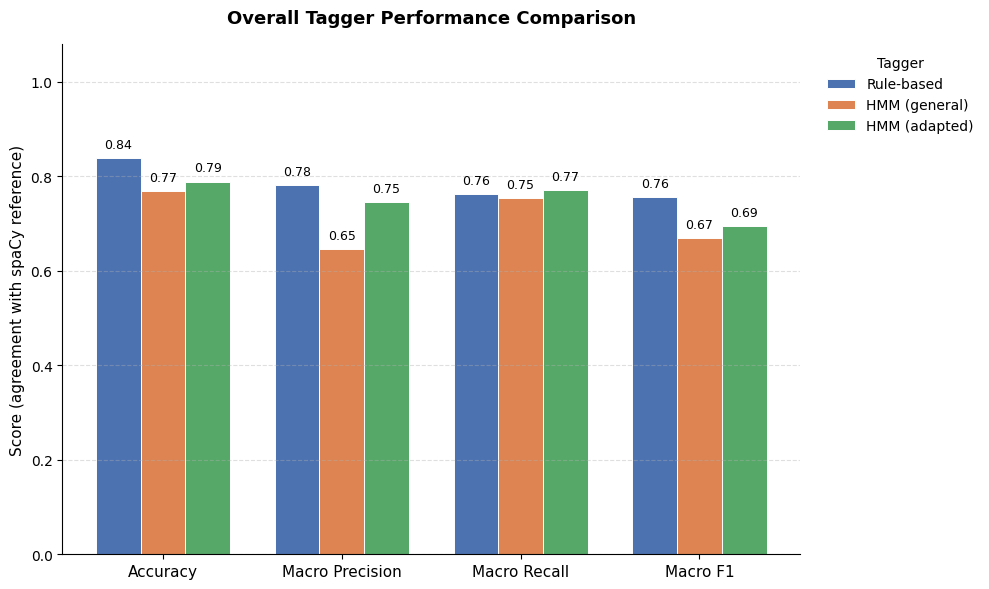

In [ ]:
x = np.arange(len(metrics_names))   # 4 metric groups
width = 0.25                         # width per bar
colors = ['#4C72B0', '#DD8452', '#55A868']  # rule-based, hmm-general, hmm-adapted

fig, ax = plt.subplots(figsize=(10, 6))

for i, tagger in enumerate(taggers):
    values = data[tagger]
    positions = x + (i - 1) * width
    bars = ax.bar(positions, values, width, label=tagger, color=colors[i], edgecolor='white', linewidth=0.7)
    # value labels on top of each bar
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.015, f"{val:.2f}",
                 ha='center', va='bottom', fontsize=9, fontweight='medium')

ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=11)
ax.set_ylabel("Score (agreement with spaCy reference)", fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_title("Overall Tagger Performance Comparison", fontsize=13, fontweight='bold', pad=15)
ax.legend(title="Tagger", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("chart1_overall_metrics.png", dpi=150, bbox_inches='tight')
plt.show()

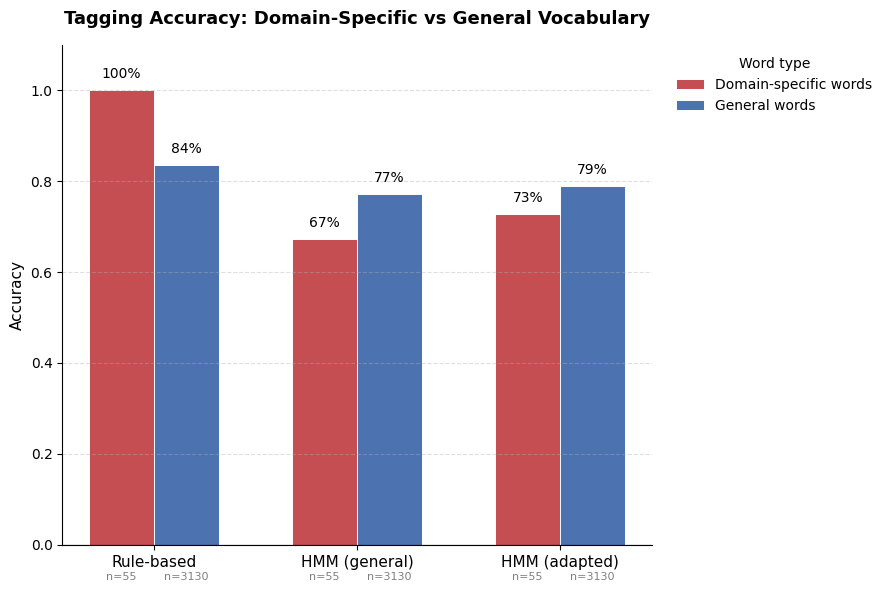

In [ ]:
labels = list(results.keys())  # ["Rule-based", "HMM (general)", "HMM (adapted)"]
dom_accs = [results[k][0] for k in labels]
gen_accs = [results[k][1] for k in labels]
dom_n = [results[k][2] for k in labels]
gen_n = [results[k][3] for k in labels]

x = np.arange(len(labels))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(x - width/2, dom_accs, width, label='Domain-specific words',
                color='#C44E52', edgecolor='white', linewidth=0.7)
bars2 = ax.bar(x + width/2, gen_accs, width, label='General words',
                color='#4C72B0', edgecolor='white', linewidth=0.7)

# value labels with sample size (n) underneath
for bar, val, n in zip(bars1, dom_accs, dom_n):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.0%}",
             ha='center', va='bottom', fontsize=10, fontweight='medium')
    ax.text(bar.get_x() + bar.get_width()/2, -0.06, f"n={n}",
             ha='center', va='top', fontsize=8, color='gray')

for bar, val, n in zip(bars2, gen_accs, gen_n):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.0%}",
             ha='center', va='bottom', fontsize=10, fontweight='medium')
    ax.text(bar.get_x() + bar.get_width()/2, -0.06, f"n={n}",
             ha='center', va='top', fontsize=8, color='gray')

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_ylim(0, 1.1)
ax.set_title("Tagging Accuracy: Domain-Specific vs General Vocabulary", fontsize=13, fontweight='bold', pad=15)
ax.legend(title="Word type", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.axhline(0, color='black', linewidth=0.8)  # baseline so the n= labels sit cleanly below it

plt.tight_layout()
plt.savefig("chart2_domain_vs_general.png", dpi=150, bbox_inches='tight')
plt.show()

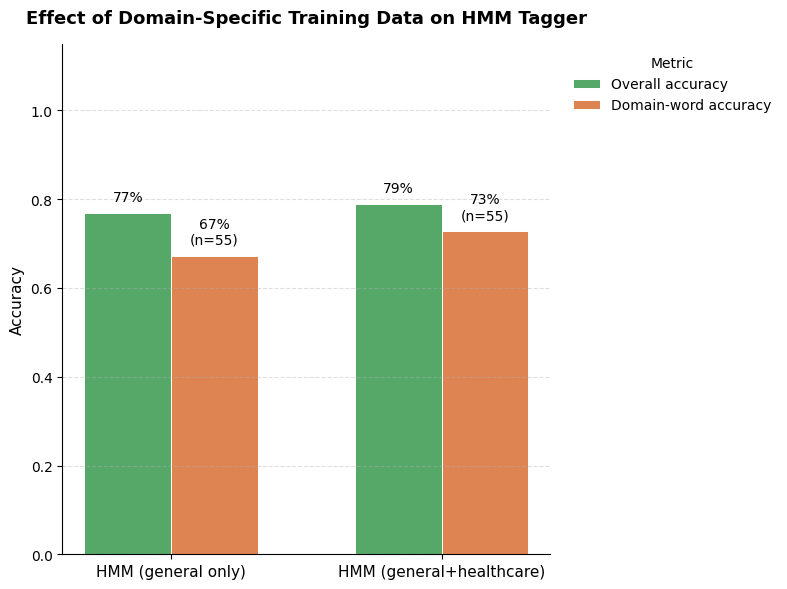

In [ ]:
adapt_labels = ["HMM (general only)", "HMM (general+healthcare)"]
adapt_accs = [hmm_general_metrics["accuracy"], hmm_adapted_metrics["accuracy"]]
adapt_dom_accs = [results["HMM (general)"][0], results["HMM (adapted)"][0]]
adapt_dom_n = [results["HMM (general)"][2], results["HMM (adapted)"][2]]

x = np.arange(len(adapt_labels))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 6))

bars1 = ax.bar(x - width/2, adapt_accs, width, label='Overall accuracy',
                color='#55A868', edgecolor='white', linewidth=0.7)
bars2 = ax.bar(x + width/2, adapt_dom_accs, width, label='Domain-word accuracy',
                color='#DD8452', edgecolor='white', linewidth=0.7)

for bar, val in zip(bars1, adapt_accs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.0%}",
             ha='center', va='bottom', fontsize=10, fontweight='medium')
for bar, val, n in zip(bars2, adapt_dom_accs, adapt_dom_n):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.0%}\n(n={n})",
             ha='center', va='bottom', fontsize=10, fontweight='medium')

ax.set_xticks(x)
ax.set_xticklabels(adapt_labels, fontsize=11)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title("Effect of Domain-Specific Training Data on HMM Tagger", fontsize=13, fontweight='bold', pad=15)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("chart3_adaptation_effect.png", dpi=150, bbox_inches='tight')
plt.show()

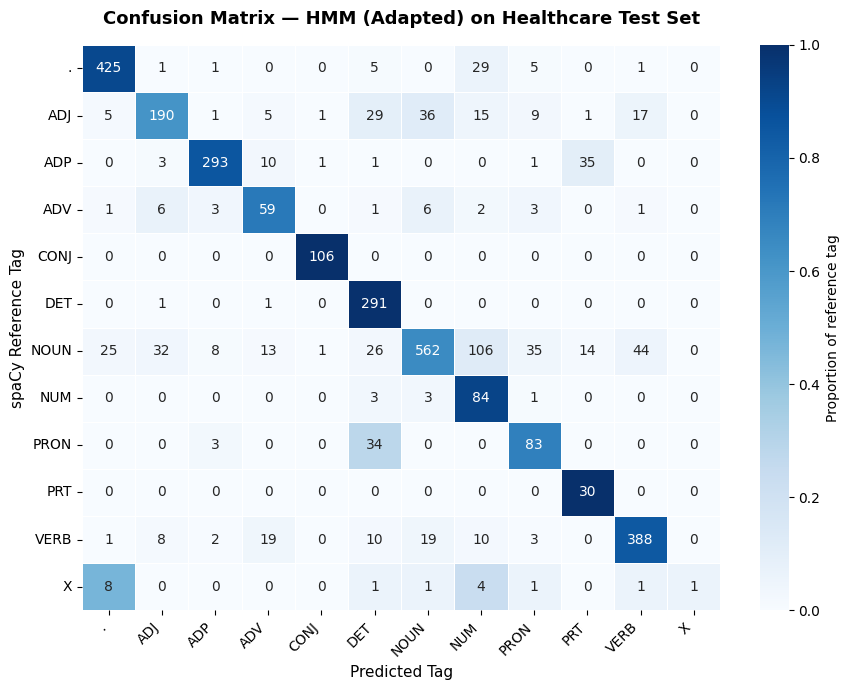

In [ ]:
# include tags that appear in either the reference or the predictions
labels_sorted = sorted(set(hmm_a_gold) | set(hmm_a_pred))
cm = confusion_matrix(hmm_a_gold, hmm_a_pred, labels=labels_sorted)

# normalize by row (reference tag) so the matrix shows % of each reference tag's predictions
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
cm_normalized = np.nan_to_num(cm_normalized)  # handle tags with zero occurrences

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm_normalized, annot=cm, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted,
            cbar_kws={'label': 'Proportion of reference tag'}, linewidths=0.5, linecolor='white', ax=ax)

ax.set_xlabel("Predicted Tag", fontsize=11)
ax.set_ylabel("spaCy Reference Tag", fontsize=11)
ax.set_title("Confusion Matrix — HMM (Adapted) on Healthcare Test Set", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("chart4_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

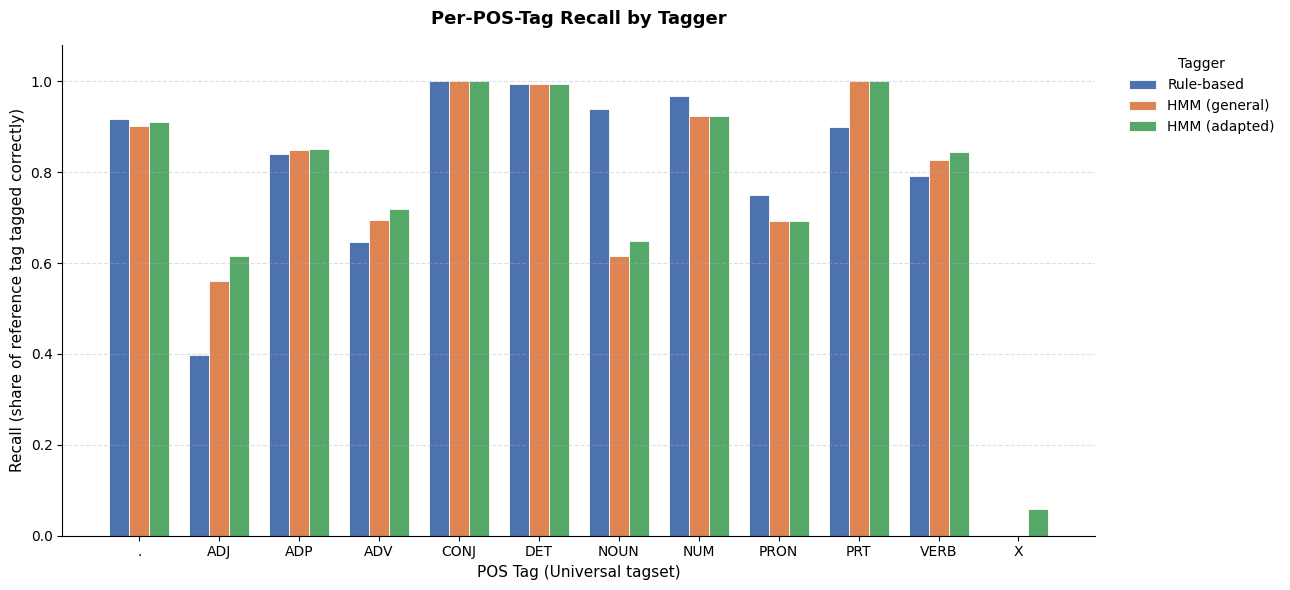

In [ ]:
def per_tag_accuracy(gold, pred):
    # share of each reference tag that was predicted correctly (= per-tag recall)
    df_tags = pd.DataFrame({"gold": gold, "pred": pred})
    return (df_tags["gold"] == df_tags["pred"]).groupby(df_tags["gold"]).mean()

tag_acc_rule = per_tag_accuracy(rule_gold, rule_pred)
tag_acc_hmm_g = per_tag_accuracy(hmm_g_gold, hmm_g_pred)
tag_acc_hmm_a = per_tag_accuracy(hmm_a_gold, hmm_a_pred)

per_tag_df = pd.DataFrame({
    "Rule-based": tag_acc_rule,
    "HMM (general)": tag_acc_hmm_g,
    "HMM (adapted)": tag_acc_hmm_a
}).fillna(0).sort_index()

tags = per_tag_df.index.tolist()
x = np.arange(len(tags))
width = 0.25
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(13, 6))

for i, col in enumerate(per_tag_df.columns):
    positions = x + (i - 1) * width
    ax.bar(positions, per_tag_df[col], width, label=col, color=colors[i], edgecolor='white', linewidth=0.6)

ax.set_xticks(x)
ax.set_xticklabels(tags, fontsize=10)
ax.set_ylabel("Recall (share of reference tag tagged correctly)", fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_xlabel("POS Tag (Universal tagset)", fontsize=11)
ax.set_title("Per-POS-Tag Recall by Tagger", fontsize=13, fontweight='bold', pad=15)
ax.legend(title="Tagger", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("chart5_per_tag_accuracy.png", dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def domain_word_errors(test_sents, tag_fn, is_hmm=False, limit=25):
    errors = []
    for sent in test_sents:
        words = [w for w, t in sent]
        gold = [t for w, t in sent]
        pred = get_predicted_tags(tag_fn, words)
        for w, g, p in zip(words, gold, pred):
            if w.lower() in domain_terms and g != p:
                errors.append((w, g, p))
    return errors[:limit]

print("Errors on domain words, shown as (word, spaCy reference tag, predicted tag)")
print("Rule-based errors:", domain_word_errors(healthcare_test, rule_based_tag, is_hmm=False))
print("HMM general errors:", domain_word_errors(healthcare_test, hmm_general.tag, is_hmm=True))
print("HMM adapted errors:", domain_word_errors(healthcare_test, hmm_adapted.tag, is_hmm=True))

Errors on domain words, shown as (word, spaCy reference tag, predicted tag)
Rule-based errors: []
HMM general errors: [('mg', 'NOUN', 'NUM'), ('IV', 'NOUN', 'NUM'), ('mmHg', 'NOUN', 'NUM'), ('mmHg', 'NOUN', 'NUM'), ('mg', 'NOUN', '.'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('incision', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('IV', 'NOUN', 'PRON'), ('nurse', 'NOUN', 'ADJ'), ('hypertension', 'NOUN', 'NUM'), ('IV', 'NOUN', 'DET'), ('anesthesia', 'NOUN', 'ADJ'), ('hemorrhage', 'NOUN', 'DET'), ('anesthesia', 'NOUN', 'PRON')]
HMM adapted errors: [('mg', 'NOUN', 'NUM'), ('IV', 'NOUN', 'NUM'), ('mmHg', 'NOUN', 'NUM'), ('mmHg', 'NOUN', 'NUM'), ('mg', 'NOUN', '.'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('incision', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('mg', 'NOUN', 'NUM'), ('IV', 'NOUN', 'PRON'), ('nurse', 'NOUN', 'ADJ'), ('hypertension', 'NOUN', 'NUM'), ('IV', 'NOUN', 'DET')]


In [ ]:
# Check: all taggers must be scored on exactly the same number of tokens
total_ref_tokens = sum(len(sent) for sent in healthcare_test)
print("Reference tokens in test set:", total_ref_tokens)
print("Rule-based tokens scored:    ", len(rule_gold))
print("HMM (general) tokens scored: ", len(hmm_g_gold))
print("HMM (adapted) tokens scored: ", len(hmm_a_gold))

for name, (dom_acc, gen_acc, dom_n, gen_n) in results.items():
    print(f"{name:15s} domain n + general n = {dom_n + gen_n}")

assert len(rule_gold) == len(hmm_g_gold) == len(hmm_a_gold) == total_ref_tokens
assert rule_gold == hmm_g_gold == hmm_a_gold, "Reference tags differ between taggers"
print("OK: all three taggers were evaluated on identical tokens and reference tags.")

Reference tokens in test set: 3185
Rule-based tokens scored:     3185
HMM (general) tokens scored:  3185
HMM (adapted) tokens scored:  3185
Rule-based      domain n + general n = 3185
HMM (general)   domain n + general n = 3185
HMM (adapted)   domain n + general n = 3185
OK: all three taggers were evaluated on identical tokens and reference tags.


In [ ]:
# Check: no whitespace in sentences or reference tokens, and predictions match reference tokens
bad_sentences = [s for s in healthcare_pool if s != " ".join(s.split())]
print("Sentences with extra whitespace:", len(bad_sentences))

all_ref_tokens = [w for sent in gold_tagged for w, t in sent]
space_only = [w for w in all_ref_tokens if w.strip() == ""]
has_space = [w for w in all_ref_tokens if any(c.isspace() for c in w)]
print("Whitespace-only reference tokens:", len(space_only))
print("Reference tokens containing whitespace:", len(has_space))

test_ref_tags = [t for sent in healthcare_test for w, t in sent]
print("Reference tokens in test set:", len(test_ref_tags))
print("Rule-based predictions:      ", len(rule_pred))
print("HMM (general) predictions:   ", len(hmm_g_pred))
print("HMM (adapted) predictions:   ", len(hmm_a_pred))

assert len(bad_sentences) == 0, "Some sentences still contain extra whitespace"
assert len(space_only) == 0 and len(has_space) == 0, "Whitespace tokens found in reference data"
assert len(rule_pred) == len(hmm_g_pred) == len(hmm_a_pred) == len(test_ref_tags)
assert rule_gold == hmm_g_gold == hmm_a_gold == test_ref_tags, "Reference tags differ between taggers"
print("OK: no whitespace tokens, and all three taggers match the same reference tokens and tags.")

Sentences with extra whitespace: 0
Whitespace-only reference tokens: 0
Reference tokens containing whitespace: 0
Reference tokens in test set: 3185
Rule-based predictions:       3185
HMM (general) predictions:    3185
HMM (adapted) predictions:    3185
OK: no whitespace tokens, and all three taggers match the same reference tokens and tags.


In [ ]:
# Summary computed from this run (all scores = agreement with spaCy reference tags)
all_metrics = {"Rule-based": rule_metrics, "HMM (general)": hmm_general_metrics, "HMM (adapted)": hmm_adapted_metrics}
for name, m in all_metrics.items():
    print(f"{name:15s} accuracy={m['accuracy']:.2%}  macro F1={m['f1']:.3f}")

best = max(all_metrics, key=lambda k: all_metrics[k]["accuracy"])
print(f"\nHighest accuracy on this test set: {best}")
print(f"Change from adding {len(healthcare_train)} healthcare sentences to the HMM: "
      f"{hmm_adapted_metrics['accuracy'] - hmm_general_metrics['accuracy']:+.2%} accuracy")
print(f"Test set size: {len(healthcare_test)} sentences, {total_ref_tokens} tokens")

Rule-based      accuracy=83.89%  macro F1=0.757
HMM (general)   accuracy=76.92%  macro F1=0.669
HMM (adapted)   accuracy=78.87%  macro F1=0.695

Highest accuracy on this test set: Rule-based
Change from adding 40 healthcare sentences to the HMM: +1.95% accuracy
Test set size: 160 sentences, 3185 tokens


In [ ]:
# Reliability check: sentence-level bootstrap confidence intervals.
# Each test sentence comes from a different report, so resampling sentences also resamples reports.
# These intervals quantify uncertainty from this held-out sample; they do not fix silver-label bias.

BOOTSTRAP_SEED = 2026
BOOTSTRAP_REPS = 2000
rng = np.random.default_rng(BOOTSTRAP_SEED)

test_gold_by_sentence = [[tag for word, tag in sent] for sent in healthcare_test]
pred_by_model = {
    "Rule-based": [get_predicted_tags(rule_based_tag, [w for w, t in sent]) for sent in healthcare_test],
    "HMM (general)": [get_predicted_tags(hmm_general.tag, [w for w, t in sent]) for sent in healthcare_test],
    "HMM (adapted)": [get_predicted_tags(hmm_adapted.tag, [w for w, t in sent]) for sent in healthcare_test],
}

def sentence_bootstrap_metrics(gold_sents, pred_sents, n_boot=BOOTSTRAP_REPS):
    """Return percentile 95% CIs for token accuracy and macro-F1, resampling whole sentences."""
    n_sent = len(gold_sents)
    estimates = []
    for _ in range(n_boot):
        sampled = rng.integers(0, n_sent, size=n_sent)
        gold = [tag for i in sampled for tag in gold_sents[i]]
        pred = [tag for i in sampled for tag in pred_sents[i]]
        acc = accuracy_score(gold, pred)
        f1 = precision_recall_fscore_support(
            gold, pred, average="macro", zero_division=0
        )[2]
        estimates.append((acc, f1))
    arr = np.asarray(estimates)
    return {
        "accuracy_ci": tuple(np.percentile(arr[:, 0], [2.5, 97.5])),
        "macro_f1_ci": tuple(np.percentile(arr[:, 1], [2.5, 97.5])),
    }

bootstrap_results = {}
for name in pred_by_model:
    bootstrap_results[name] = sentence_bootstrap_metrics(
        test_gold_by_sentence, pred_by_model[name]
    )

print("Sentence-level bootstrap 95% confidence intervals (2,000 resamples)")
for name, ci in bootstrap_results.items():
    print(
        f"{name:15s} | accuracy={all_metrics[name]['accuracy']:.3f} "
        f"95% CI [{ci['accuracy_ci'][0]:.3f}, {ci['accuracy_ci'][1]:.3f}] "
        f"| macro-F1={all_metrics[name]['f1']:.3f} "
        f"95% CI [{ci['macro_f1_ci'][0]:.3f}, {ci['macro_f1_ci'][1]:.3f}]"
    )

# Paired bootstrap of token-accuracy differences: all models are tested on the same sentences.
# Resampling the same sentence indices for both models preserves the paired design.
delta_accuracy = []
n_sent = len(healthcare_test)
for _ in range(BOOTSTRAP_REPS):
    sampled = rng.integers(0, n_sent, size=n_sent)
    gold = [tag for i in sampled for tag in test_gold_by_sentence[i]]
    pred_general = [tag for i in sampled for tag in pred_by_model["HMM (general)"][i]]
    pred_adapted = [tag for i in sampled for tag in pred_by_model["HMM (adapted)"][i]]
    delta_accuracy.append(
        accuracy_score(gold, pred_adapted) - accuracy_score(gold, pred_general)
    )
delta_ci = np.percentile(delta_accuracy, [2.5, 97.5])
observed_delta = hmm_adapted_metrics["accuracy"] - hmm_general_metrics["accuracy"]
print(
    f"\nPaired bootstrap: adapted minus general HMM accuracy = {observed_delta:+.3f}; "
    f"95% CI [{delta_ci[0]:+.3f}, {delta_ci[1]:+.3f}]"
)
if delta_ci[0] > 0 or delta_ci[1] < 0:
    print("The paired 95% interval excludes zero in this sample; interpret cautiously.")
else:
    print("The paired 95% interval includes zero; this sample does not show a clear difference.")


Sentence-level bootstrap 95% confidence intervals (2,000 resamples)
Rule-based      | accuracy=0.839 95% CI [0.825, 0.852] | macro-F1=0.757 95% CI [0.739, 0.772]
HMM (general)   | accuracy=0.769 95% CI [0.751, 0.787] | macro-F1=0.669 95% CI [0.646, 0.689]
HMM (adapted)   | accuracy=0.789 95% CI [0.771, 0.806] | macro-F1=0.695 95% CI [0.668, 0.722]

Paired bootstrap: adapted minus general HMM accuracy = +0.019; 95% CI [+0.014, +0.026]
The paired 95% interval excludes zero in this sample; interpret cautiously.


In [ ]:
# Results-based discussion generated from this run.
# Run all cells in order to populate these measured values.

all_metrics = {
    "Rule-based": rule_metrics,
    "HMM (general)": hmm_general_metrics,
    "HMM (adapted)": hmm_adapted_metrics,
}
best = max(all_metrics, key=lambda name: all_metrics[name]["accuracy"])
print("DISCUSSION OF RESULTS")
print("=" * 60)
print(f"The highest overall agreement with the spaCy reference labels was achieved by {best} "
      f"(accuracy={all_metrics[best]['accuracy']:.3f}, macro-F1={all_metrics[best]['f1']:.3f}).")
for name, metrics in all_metrics.items():
    ci = bootstrap_results[name]
    print(f"{name}: accuracy={metrics['accuracy']:.3f} "
          f"(sentence-bootstrap 95% CI {ci['accuracy_ci'][0]:.3f}–{ci['accuracy_ci'][1]:.3f}); "
          f"macro-F1={metrics['f1']:.3f} "
          f"(95% CI {ci['macro_f1_ci'][0]:.3f}–{ci['macro_f1_ci'][1]:.3f}).")

change = hmm_adapted_metrics["accuracy"] - hmm_general_metrics["accuracy"]
print(f"\nAdding {len(healthcare_train)} healthcare sentences changed HMM accuracy by "
      f"{change:+.3f} ({change*100:+.2f} percentage points).")
print(f"Paired bootstrap 95% CI for adapted-minus-general accuracy: "
      f"[{delta_ci[0]:+.3f}, {delta_ci[1]:+.3f}].")

print("\nDOMAIN-SPECIFIC VS GENERAL WORDS")
for name, (domain_acc, general_acc, domain_n, general_n) in results.items():
    print(f"{name}: curated domain-term accuracy={domain_acc:.3f} (n={domain_n}); "
          f"other-word accuracy={general_acc:.3f} (n={general_n}).")

print("\nWORDS UNSEEN IN PENN TREEBANK (case-insensitive)")
for name, (oov_acc, iv_acc, oov_n, iv_n) in oov_results.items():
    print(f"{name}: unseen-word accuracy={oov_acc:.3f} (n={oov_n}); "
          f"seen-word accuracy={iv_acc:.3f} (n={iv_n}).")

print("\nINTERPRETATION")
print("All reported scores are agreement with automatic spaCy reference labels, not human-verified gold tags.")
print("The rule-based tagger uses a hand-built medical lexicon; its score on those exact terms is partly built in.")
print("The bootstrap intervals describe uncertainty across this held-out sample, not systematic labelling bias.")
print("A CI that includes zero for the paired accuracy difference does not support a clear improvement in this sample.")


DISCUSSION OF RESULTS
The highest overall agreement with the spaCy reference labels was achieved by Rule-based (accuracy=0.839, macro-F1=0.757).
Rule-based: accuracy=0.839 (sentence-bootstrap 95% CI 0.825–0.852); macro-F1=0.757 (95% CI 0.739–0.772).
HMM (general): accuracy=0.769 (sentence-bootstrap 95% CI 0.751–0.787); macro-F1=0.669 (95% CI 0.646–0.689).
HMM (adapted): accuracy=0.789 (sentence-bootstrap 95% CI 0.771–0.806); macro-F1=0.695 (95% CI 0.668–0.722).

Adding 40 healthcare sentences changed HMM accuracy by +0.019 (+1.95 percentage points).
Paired bootstrap 95% CI for adapted-minus-general accuracy: [+0.014, +0.026].

DOMAIN-SPECIFIC VS GENERAL WORDS
Rule-based: curated domain-term accuracy=1.000 (n=55); other-word accuracy=0.836 (n=3130).
HMM (general): curated domain-term accuracy=0.673 (n=55); other-word accuracy=0.771 (n=3130).
HMM (adapted): curated domain-term accuracy=0.727 (n=55); other-word accuracy=0.790 (n=3130).

WORDS UNSEEN IN PENN TREEBANK (case-insensitive)
Rul

In [66]:

# Interactive test using the existing POS taggers

sentence = input("Enter a healthcare sentence: ").strip()

if sentence:
    words = word_tokenize(sentence)

    rule_results = rule_based_tag(words)
    general_results = hmm_general.tag(words)
    adapted_results = hmm_adapted.tag(words)

    print("\nInput:", sentence)
    print("\nPOS Tagging Results")
    print("-" * 70)
    print(f"{'Word':20s}{'Rule-based':16s}{'General HMM':16s}{'Adapted HMM':16s}")
    print("-" * 70)

    for i, word in enumerate(words):
        print(
            f"{word:20s}"
            f"{rule_results[i][1]:16s}"
            f"{general_results[i][1]:16s}"
            f"{adapted_results[i][1]:16s}"
        )

    print("-" * 70)
else:
    print("Please enter a sentence.")


Enter a healthcare sentence: History of significant left lower quadrant pain managed with intravenous antibiotics and close clinical observation.

Input: History of significant left lower quadrant pain managed with intravenous antibiotics and close clinical observation.

POS Tagging Results
----------------------------------------------------------------------
Word                Rule-based      General HMM     Adapted HMM     
----------------------------------------------------------------------
History             NOUN            NOUN            NOUN            
of                  ADP             ADP             ADP             
significant         NOUN            ADJ             ADJ             
left                NOUN            VERB            ADJ             
lower               NOUN            ADJ             ADJ             
quadrant            NOUN            NOUN            NOUN            
pain                NOUN            NOUN            NOUN            
managed       